# 测试梯度

In [322]:
import  numpy as np
def loss_fu(w):
    return 0.05*w[0]**2+w[1]**2
    # return 0.05 * w[0]**2 + w[1] ** 2

In [323]:
import torch
start_w=[-7,2]
lr=0.8
epochs=500
momentum=0.1
def grad_desc(w,epochs=0,optimizer:torch.optim.Optimizer=None):
    w1_history=[]
    w2_history=[]
    for epoch in range(epochs):
        w1_history.append(w[0].item())
        w2_history.append(w[1].item())
        # w1_history.append(w[0].detach().numpy())# 这里是共享内存的
        y=loss_fu(w)
        # print(w1,w2)
        y.backward()
        optimizer.step()
        optimizer.zero_grad()
    return w1_history,w2_history

## SGD

In [324]:

sgd_start_w=torch.tensor(start_w,dtype=torch.float,requires_grad=True)
optimizer = torch.optim.SGD([sgd_start_w], lr=lr)
w1_history,w2_history=grad_desc(sgd_start_w,epochs,optimizer)

## 动量法

In [325]:
moment_start_w=torch.tensor(start_w,dtype=torch.float,requires_grad=True)
moment_optimizer = torch.optim.SGD([moment_start_w], lr=lr,momentum=momentum)
moment_w1_history,moment_w2_history=grad_desc(moment_start_w,epochs,moment_optimizer)

In [326]:
ada_start_w=torch.tensor(start_w,dtype=torch.float,requires_grad=True)
ada_optimizer = torch.optim.Adagrad([ada_start_w], lr=lr)
ada_w1_history,ada_w2_history=grad_desc(ada_start_w,epochs,ada_optimizer)

## Adam

In [327]:
ada_start_w=torch.tensor(start_w,dtype=torch.float,requires_grad=True)
adam_optimizer = torch.optim.Adam([ada_start_w], lr=lr)
adam_w1_history,adam_w2_history=grad_desc(ada_start_w,epochs,adam_optimizer)

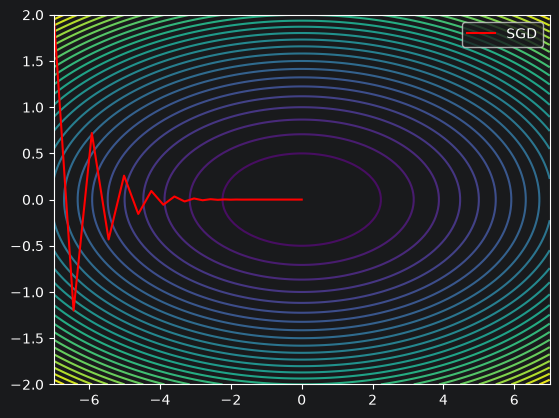

In [330]:
from matplotlib import pyplot as plt
w1=np.linspace(-7,7,100)
w2=np.linspace(-2,2,100)
W1,W2=np.meshgrid(w1,w2)
Z=loss_fu([W1,W2])
plt.contour(W1,W2,Z,levels=30)
plt.plot(w1_history,w2_history,color='red',label='SGD')
# plt.plot(moment_w1_history,moment_w2_history,color='blue',label='Moment')
# plt.plot(ada_w1_history,ada_w2_history,color='yellow',label='Adagrad')
# plt.plot(adam_w1_history,ada_w2_history,color='pink',label='Adam')
plt.legend()
plt.show()